In [1]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# DTI metrics
dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')
dti = dti[dti.isPatient == 1] # just patients
dti = dti[dti.regionname == 'CST_R']

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0

/localscratch/tmp/ipykernel_172130/1941111817.py:9: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  dti = pd.read_csv(os.path.join(gl.baseDir, 'DTI', 'WMPMII_DTI_flip.tsv'), sep = '\t')


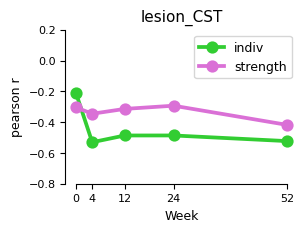

In [11]:
# affected: ipsilesional CST, paretic hand
r_indiv = {}
r_mvc = {}

for i, week in enumerate(gl.weeks):
    behav_plot = behav[behav.Week == week]
    behav_plot = behav_plot[['lesion_CST', 'indiv_norm', 'mvc_norm']].apply(pd.to_numeric, errors='coerce').dropna() # make all values numeric

    r1, p1 = stats.pearsonr(behav_plot['lesion_CST'], behav_plot['indiv_norm'])
    r_indiv.update({week: r1})

    r2, p2 = stats.pearsonr(behav_plot['lesion_CST'], behav_plot['mvc_norm'])
    r_mvc.update({week: r2})


fig, ax = plt.subplots(figsize = (3,2))
r_df_indiv = pd.DataFrame(list(r_indiv.items()), columns = ['Week', 'r_stat'])
r_df_mvc = pd.DataFrame(list(r_mvc.items()), columns = ['Week', 'r_stat'])

sns.pointplot(x=r_df_indiv['Week'], y=r_df_indiv['r_stat'], color = 'limegreen', native_scale = True, ax = ax, label = 'indiv')
sns.pointplot(x=r_df_mvc['Week'], y=r_df_mvc['r_stat'], color = 'orchid', native_scale = True, ax = ax, label = 'strength')

plt.title("lesion_CST")
plt.legend()
plt.ylabel('pearson r')
plt.xlabel('Week')
plt.xticks(gl.weeks)
plt.ylim(-.8, .2)
sns.despine(trim = True)
plt.show()